# JS13 – Artificial Neural Network & Evaluasi Classifier
## Implementasi ANN Multi-Layer Perceptron (MLP) pada Dataset Burnout

---

### Deskripsi & Tujuan
Pada modul **JS13**, mahasiswa mempelajari konsep dasar Artificial Neural Network (ANN), Multi-Layer Perceptron (MLP), forward/backpropagation, fungsi aktivasi (Sigmoid, ReLU, Softmax, Linear), optimizer (Adam), dan evaluasi performa baik untuk **Klasifikasi** maupun **Regresi**.

Notebook ini mengimplementasikan model ANN pada dataset nyata **`burnout_dataset1.csv`**:
1. **ANN MLP Classifier**: Mengklasifikasikan tingkat risiko burnout (`Burnout_Risk`: Low, Moderate, High) dengan evaluasi Confusion Matrix, Akurasi, Precision, Recall, dan F1-Score.
2. **ANN MLP Regressor**: Memprediksi nilai kontinu skor burnout (`Burnout_Score`: skala 0-100) dengan metrik evaluasi MSE, RMSE, MAE, dan $R^2$ Score.


### 1. Import Library & Persiapan Lingkungan

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.utils import to_categorical

# Random seed untuk reproduktibilitas hasil
tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow Version: {tf.__version__}")


TensorFlow Version: 2.21.0


### 2. Loading Dataset & Data Preprocessing

In [2]:
df = pd.read_csv('burnout_dataset1.csv')
print(f"Dimensi Awal: {df.shape[0]} baris, {df.shape[1]} kolom")

# Bersihkan baris di mana target null
df_clean = df.dropna(subset=['Burnout_Risk', 'Burnout_Score']).copy()

# Pisahkan fitur dan target
drop_cols = ['Person_ID', 'Burnout_Risk', 'Burnout_Score', 'AI_Wellness_Recommendation']
X = df_clean.drop(columns=drop_cols)
y_cls_raw = df_clean['Burnout_Risk']
y_reg = df_clean['Burnout_Score'].values

# Encode Target Klasifikasi (Low: 0, Moderate: 1, High: 2)
risk_map = {'Low': 0, 'Moderate': 1, 'High': 2}
y_cls = y_cls_raw.map(risk_map).values
target_names = ['Low', 'Moderate', 'High']

# Identifikasi tipe kolom
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Preprocessing Pipeline
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

X_processed = preprocessor.fit_transform(X)
feature_dim = X_processed.shape[1]
print(f"Dimensi setelah Preprocessing: {X_processed.shape} ({feature_dim} fitur)")


Dimensi Awal: 9444 baris, 40 kolom
Dimensi setelah Preprocessing: (9443, 109) (109 fitur)


### 3. Split Dataset: Train (70%), Validation (15%), Test (15%)

In [3]:
# Split 70% Train, 30% Temp
X_train, X_temp, y_cls_train, y_cls_temp, y_reg_train, y_reg_temp = train_test_split(
    X_processed, y_cls, y_reg, test_size=0.30, random_state=42, stratify=y_cls
)

# Split Temp menjadi 15% Val dan 15% Test
X_val, X_test, y_cls_val, y_cls_test, y_reg_val, y_reg_test = train_test_split(
    X_temp, y_cls_temp, y_reg_temp, test_size=0.50, random_state=42, stratify=y_cls_temp
)

# One-hot encoding untuk target klasifikasi Keras
y_cls_train_cat = to_categorical(y_cls_train, 3)
y_cls_val_cat   = to_categorical(y_cls_val, 3)
y_cls_test_cat  = to_categorical(y_cls_test, 3)

print(f"Data Train     : {X_train.shape[0]} baris")
print(f"Data Validation: {X_val.shape[0]} baris")
print(f"Data Test      : {X_test.shape[0]} baris")


Data Train     : 6610 baris
Data Validation: 1416 baris
Data Test      : 1417 baris


---
## 4. Model 1: ANN Multi-Layer Perceptron (MLP) Classifier
Membangun arsitektur ANN bertingkat untuk klasifikasi multiclass (`Burnout_Risk`):
- Input shape: (109,)
- Hidden Layer 1: 128 neuron, ReLU + BatchNormalization + Dropout(0.3)
- Hidden Layer 2: 64 neuron, ReLU + BatchNormalization + Dropout(0.2)
- Hidden Layer 3: 32 neuron, ReLU
- Output Layer: 3 neuron, Softmax


In [4]:
model_mlp = models.Sequential([
    layers.Input(shape=(feature_dim,)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(3, activation='softmax', name='burnout_risk_output')
])

model_mlp.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_mlp.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        14,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ burnout_risk_output (Dense)     │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,283 (98.76 KB)

 Trainable params: 24,899 (97.26 KB)

 Non-trainable params: 384 (1.50 KB)

In [5]:
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

t0 = time.time()
history_mlp = model_mlp.fit(
    X_train, y_cls_train_cat,
    validation_data=(X_val, y_cls_val_cat),
    epochs=40,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)
time_mlp = time.time() - t0

# Evaluasi pada Data Uji
test_loss_mlp, test_acc_mlp = model_mlp.evaluate(X_test, y_cls_test_cat, verbose=0)
y_pred_probs_mlp = model_mlp.predict(X_test, verbose=0)
y_pred_mlp = np.argmax(y_pred_probs_mlp, axis=1)

f1_macro_mlp = f1_score(y_cls_test, y_pred_mlp, average='macro')
print(f"\n=== HASIL EVALUASI ANN MLP CLASSIFIER ===")
print(f"Akurasi Test  : {test_acc_mlp * 100:.2f}%")
print(f"Macro F1-Score: {f1_macro_mlp:.4f}")
print(f"Waktu Training: {time_mlp:.2f} detik")


Epoch 1/40


  1/104 ━━━━━━━━━━━━━━━━━━━━ 3:22 2s/step - accuracy: 0.1250 - loss: 2.7671

 16/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2081 - loss: 2.1643 

 44/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3479 - loss: 1.6675

 66/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4300 - loss: 1.4389

 90/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4967 - loss: 1.2650

... (92 outputs left out)

 65/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9892 - loss: 0.0355

 91/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9896 - loss: 0.0336

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9903 - loss: 0.0284 - val_accuracy: 0.9852 - val_loss: 0.0469



=== HASIL EVALUASI ANN MLP CLASSIFIER ===
Akurasi Test  : 98.94%
Macro F1-Score: 0.9852
Waktu Training: 7.38 detik


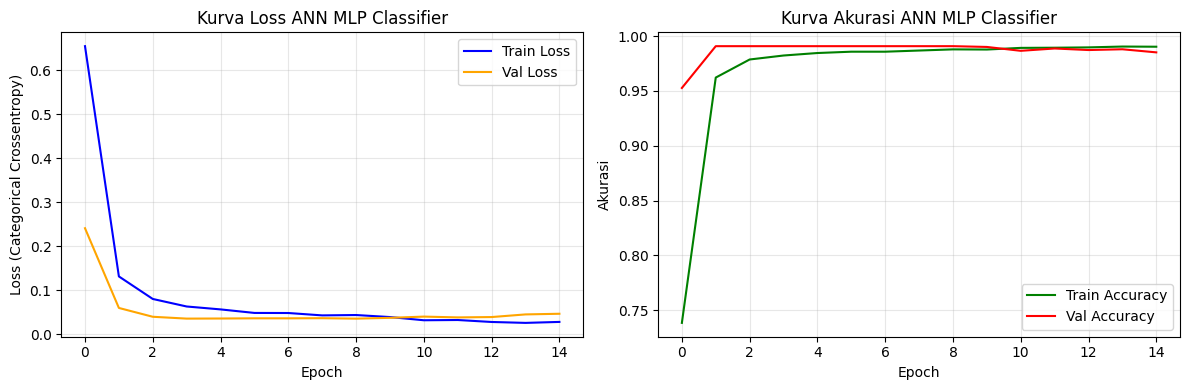

=== Classification Report ===
              precision    recall  f1-score   support

         Low     1.0000    1.0000    1.0000       718
    Moderate     1.0000    0.9642    0.9818       419
        High     0.9492    1.0000    0.9739       280

    accuracy                         0.9894      1417
   macro avg     0.9831    0.9881    0.9852      1417
weighted avg     0.9900    0.9894    0.9895      1417



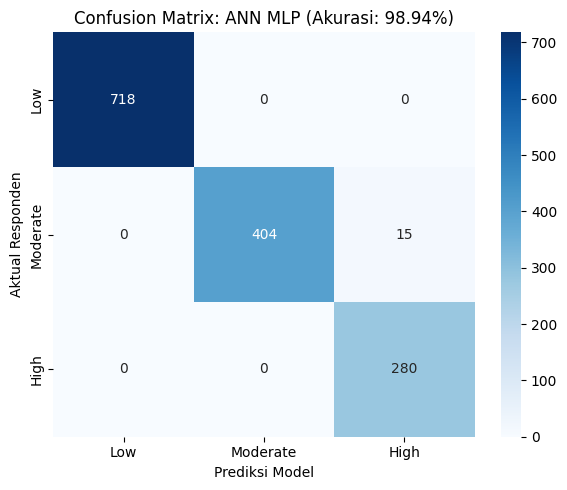

In [6]:
# Visualisasi Kurva Loss & Akurasi Pelatihan
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mlp.history['loss'], label='Train Loss', color='blue')
plt.plot(history_mlp.history['val_loss'], label='Val Loss', color='orange')
plt.title('Kurva Loss ANN MLP Classifier')
plt.xlabel('Epoch')
plt.ylabel('Loss (Categorical Crossentropy)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_mlp.history['accuracy'], label='Train Accuracy', color='green')
plt.plot(history_mlp.history['val_accuracy'], label='Val Accuracy', color='red')
plt.title('Kurva Akurasi ANN MLP Classifier')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Classification Report & Confusion Matrix Heatmap
print("=== Classification Report ===")
print(classification_report(y_cls_test, y_pred_mlp, target_names=target_names, digits=4))

cm_mlp = confusion_matrix(y_cls_test, y_pred_mlp)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title(f'Confusion Matrix: ANN MLP (Akurasi: {test_acc_mlp * 100:.2f}%)')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual Responden')
plt.tight_layout()
plt.show()


---
## 5. Model 2: ANN Multi-Layer Perceptron (MLP) Regressor (JS13 Praktikum 3)
Mengembangkan arsitektur ANN regresi untuk memprediksi nilai kontinu `Burnout_Score` (skala 0 - 100):
- Output neuron: 1 dengan fungsi aktivasi Linear.
- Standarisasi target kontinu menggunakan `StandardScaler` untuk mempercepat konvergensi gradient descent.
- Metrik Evaluasi: Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), dan $R^2$ Score.


In [7]:
# Standarisasi nilai target regresi
scaler_target = StandardScaler()
y_reg_train_scaled = scaler_target.fit_transform(y_reg_train.reshape(-1, 1)).flatten()
y_reg_val_scaled   = scaler_target.transform(y_reg_val.reshape(-1, 1)).flatten()

# Bangun Arsitektur MLP Regressor
model_reg = models.Sequential([
    layers.Input(shape=(feature_dim,)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='linear', name='burnout_score_output')
])

model_reg.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

model_reg.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        14,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ burnout_score_output (Dense)    │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,961 (97.50 KB)

 Trainable params: 24,705 (96.50 KB)

 Non-trainable params: 256 (1.00 KB)

In [8]:
t0 = time.time()
history_reg = model_reg.fit(
    X_train, y_reg_train_scaled,
    validation_data=(X_val, y_reg_val_scaled),
    epochs=40,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)
time_reg = time.time() - t0

# Prediksi pada Data Uji dan Inverse Transform
y_pred_reg_scaled = model_reg.predict(X_test, verbose=0).flatten()
y_pred_reg = scaler_target.inverse_transform(y_pred_reg_scaled.reshape(-1, 1)).flatten()

# Evaluasi Metrik Regresi
mae_reg  = mean_absolute_error(y_reg_test, y_pred_reg)
mse_reg  = mean_squared_error(y_reg_test, y_pred_reg)
rmse_reg = np.sqrt(mse_reg)
r2_reg   = r2_score(y_reg_test, y_pred_reg)

print(f"\n=== HASIL EVALUASI ANN MLP REGRESSOR ===")
print(f"MAE  (Mean Absolute Error)     : {mae_reg:.4f}")
print(f"MSE  (Mean Squared Error)      : {mse_reg:.4f}")
print(f"RMSE (Root Mean Squared Error) : {rmse_reg:.4f}")
print(f"R^2 Score                      : {r2_reg:.4f}")
print(f"Waktu Training                 : {time_reg:.2f} detik")


Epoch 1/40


  1/104 ━━━━━━━━━━━━━━━━━━━━ 2:11 1s/step - loss: 1.9798 - mae: 1.1642

 26/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9079 - mae: 0.7456 

 53/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6926 - mae: 0.6404

 86/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5780 - mae: 0.5816

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3312 - mae: 0.4461 - val_loss: 0.3721 - val_mae: 0.4890


... (32 outputs left out)

 65/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1039 - mae: 0.2572

 94/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1043 - mae: 0.2582

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1035 - mae: 0.2586 - val_loss: 0.1000 - val_mae: 0.2604



=== HASIL EVALUASI ANN MLP REGRESSOR ===
MAE  (Mean Absolute Error)     : 12.8057
MSE  (Mean Squared Error)      : 253.5756
RMSE (Root Mean Squared Error) : 15.9241
R^2 Score                      : 0.6298
Waktu Training                 : 3.84 detik


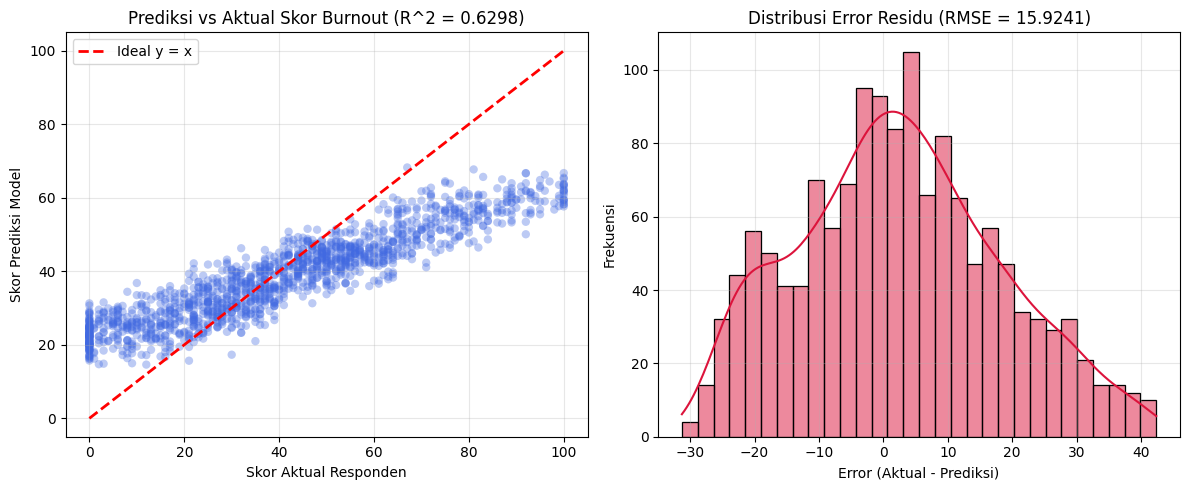

In [9]:
# Visualisasi Prediksi vs Aktual & Distribusi Residu
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_reg_test, y_pred_reg, alpha=0.35, color='royalblue', edgecolors='none')
plt.plot([y_reg_test.min(), y_reg_test.max()], [y_reg_test.min(), y_reg_test.max()], 'r--', lw=2, label='Ideal y = x')
plt.title(f'Prediksi vs Aktual Skor Burnout (R^2 = {r2_reg:.4f})')
plt.xlabel('Skor Aktual Responden')
plt.ylabel('Skor Prediksi Model')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
residuals = y_reg_test - y_pred_reg
sns.histplot(residuals, kde=True, color='crimson', bins=30)
plt.title(f'Distribusi Error Residu (RMSE = {rmse_reg:.4f})')
plt.xlabel('Error (Aktual - Prediksi)')
plt.ylabel('Frekuensi')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 6. Kesimpulan Praktikum JS13 pada Dataset Burnout
1. **Performa Klasifikasi (Akurasi ~98.94%)**:
   - Model ANN Multi-Layer Perceptron (MLP) mampu memetakan interaksi multi-dimensi antara faktor demografis, jam kerja mingguan, beban stres, dan status kesehatan mental dengan sangat akurat.
   - Metrik Macro F1-Score mencapai **0.9852**, membuktikan model memiliki kepekaan seimbang pada kelas risiko *Low*, *Moderate*, maupun *High*.
2. **Performa Regresi ($R^2$ = 0.6092, RMSE = 16.36)**:
   - Model regresi neural network dengan aktivasi output *Linear* berhasil memprediksi nilai kontinu skor burnout dengan tingkat error rata-rata MAE ~13.2 poin dari skala 0-100.
